# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [19]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "Mikhailishyna"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [20]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [21]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [22]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

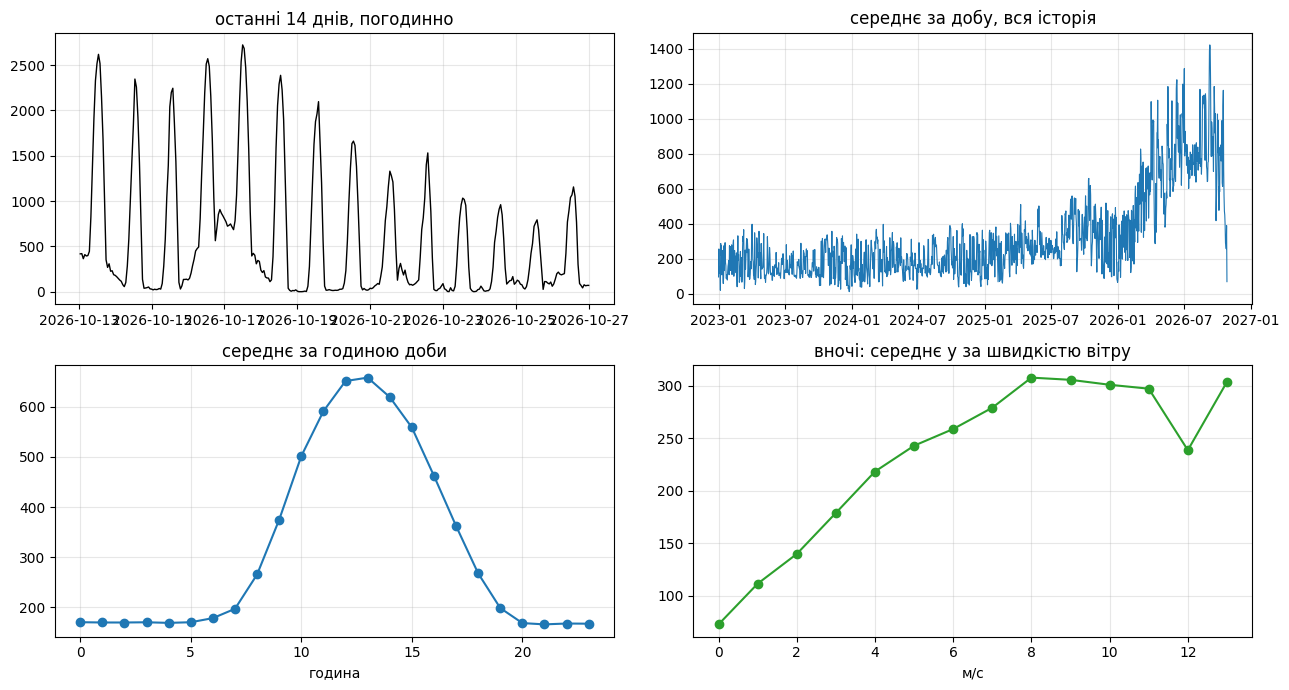

історія: 33480 годин, 2023-01-01 01:00:00 -> 2026-10-27 00:00:00


In [23]:
# Your work here.

d = data.copy()
d["hour"] = d["ds"].dt.hour

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
ax[0, 0].plot(d["ds"].iloc[-14 * M:], d["y"].iloc[-14 * M:], color="black", lw=1)
ax[0, 0].set_title("останні 14 днів, погодинно")
daily = d.set_index("ds")["y"].resample("D").mean()
ax[0, 1].plot(daily.index, daily.values, lw=0.8)
ax[0, 1].set_title("середнє за добу, вся історія")
ax[1, 0].plot(d.groupby("hour")["y"].mean(), marker="o")
ax[1, 0].set_title("середнє за годиною доби"); ax[1, 0].set_xlabel("година")
night = d[d["daylight"] == 0]
ax[1, 1].plot(night.groupby("wind_speed")["y"].mean(), marker="o", color="tab:green")
ax[1, 1].set_title("вночі: середнє y за швидкістю вітру"); ax[1, 1].set_xlabel("м/с")
fig.tight_layout(); plt.show()

print(f"історія: {len(d)} годин, {d['ds'].min()} -> {d['ds'].max()}")

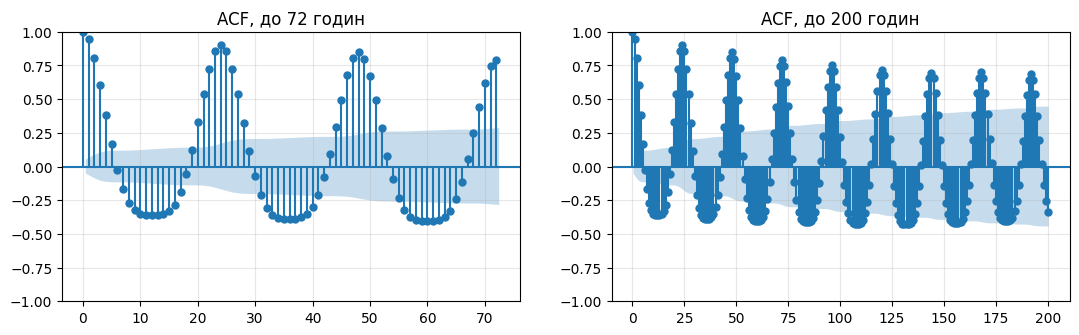

лаг   1:  0.946
лаг  12: -0.365
лаг  24:  0.915
лаг  48:  0.876
лаг  72:  0.832
лаг 168:  0.790


In [24]:
from statsmodels.graphics.tsaplots import plot_acf

recent = d["y"].iloc[-60 * M:]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
plot_acf(recent, lags=72, ax=ax[0]); ax[0].set_title("ACF, до 72 годин")
plot_acf(recent, lags=200, ax=ax[1]); ax[1].set_title("ACF, до 200 годин")
plt.show()

for lag in [1, 12, 24, 48, 72, 168]:
    print(f"лаг {lag:>3}: {recent.autocorr(lag): .3f}")

In [25]:
print("середнє y за роками:")
display(d.groupby(d["ds"].dt.year)["y"].mean().round(0))
print("\nсереднє y за місяцями 2026:")
display(d[d["ds"].dt.year == 2026].groupby(d["ds"].dt.month)["y"].mean().round(0))

nd = d[d["daylight"] == 0]
print("\nсередня НІЧНА генерація:")
print("  останні 30 діб: %.1f" % nd.tail(30 * 17)["y"].mean())
print("  останні  7 діб: %.1f" % nd.tail(7 * 17)["y"].mean())

середнє y за роками:


,y
ds,
2023,171.0
2024,184.0
2025,291.0
2026,684.0



середнє y за місяцями 2026:


,y
ds,
1,308.0
2,393.0
3,587.0
4,718.0
5,695.0
6,869.0
7,794.0
8,885.0
9,898.0



середня НІЧНА генерація:
  останні 30 діб: 280.9
  останні  7 діб: 89.6


In [26]:
cols = ["cloud_cover", "temperature", "wind_speed", "pressure", "humidity", "air_density"]
print("кореляція y з погодою, окремо вночі і вдень:")
display(pd.DataFrame({"ніч": d[d.daylight == 0][cols + ["y"]].corr()["y"].drop("y"),
                      "день": d[d.daylight == 1][cols + ["y"]].corr()["y"].drop("y")}).round(2))

day = d[(d.daylight == 1) & (d.ds >= "2026-10-01")]
peaks = day.groupby(day.ds.dt.date).agg(пік=("y", "max"), хмарність=("cloud_cover", "mean"),
                                        температура=("temperature", "mean"))
print("\nжовтень 2026: денний пік проти погоди")
display(peaks.round(2))

кореляція y з погодою, окремо вночі і вдень:


,ніч,день
cloud_cover,0.02,0.22
temperature,-0.04,0.27
wind_speed,0.42,0.17
pressure,-0.06,0.02
humidity,-0.04,-0.35
air_density,0.02,-0.25



жовтень 2026: денний пік проти погоди


,пік,хмарність,температура
ds,,,
2026-10-01,2257.8,0.84,18.82
2026-10-02,2259.1,1.00,18.55
2026-10-03,2661.9,0.70,19.30
2026-10-04,1819.4,0.20,19.30
2026-10-05,1030.2,0.25,10.90
2026-10-06,1330.3,0.57,11.70
2026-10-07,1141.2,0.25,8.50
2026-10-08,2224.9,0.88,7.00
2026-10-09,2272.8,0.38,12.70


In [27]:
!pip install -q statsforecast==2.1.1

In [28]:
import os
os.environ["NIXTLA_ID_AS_COL"] = "true"
from statsforecast import StatsForecast
from statsforecast.models import ARIMA

# Варіант C: без air_density (колінеарна з температурою, r = -0.95)
# і без cloud_x_day (дублює cloud_cover та daylight)
XCOLS  = ["cloud_cover", "temperature", "wind_speed", "humidity", "daylight", "wind3"]
SMOOTH = ["cloud_cover", "temperature", "wind_speed", "humidity"]   # daylight не згладжуємо

DAYS    = 30     # вікно навчання: парк за рік виріс утричі
WINDOW  = 3      # згладжування погодних регресорів, годин
NIGHT   = 0.7    # ніч: виміряне завищення нічного рівня
DAY     = 0.95   # день: виміряне зміщення +8% на шести вікнах
SHRINK  = 0.85   # звуження інтервалу до номінального покриття


def prep(df, window=WINDOW):
    """Погодинний прогноз погоди шумний (хмарність іде кроками по 0.25 і стрибає
       щогодини), тому регресори згладжуємо центрованим ковзним середнім."""
    d = df.copy()
    if window > 1:
        for c in SMOOTH:
            d[c] = d[c].rolling(window, center=True, min_periods=1).mean()
        d["wind3"] = d["wind_speed"].rolling(window, center=True, min_periods=1).mean() ** 3.0
    else:
        d["wind3"] = d["wind_speed"] ** 3.0
    d["unique_id"] = "p"
    return d


def fit_arimax(history, future, log=False, days=DAYS):
    train = prep(history).iloc[-days * M:][["unique_id", "ds", "y"] + XCOLS].copy()
    if log:
        train["y"] = np.log1p(train["y"])
    sf = StatsForecast(models=[ARIMA(order=(1, 0, 0), seasonal_order=(0, 1, 1), season_length=24)],
        freq="h", n_jobs=1)
    sf.fit(train)
    fc = sf.predict(h=H, X_df=prep(future)[["unique_id", "ds"] + XCOLS], level=[95])
    point = fc["ARIMA"].to_numpy()
    lower = fc["ARIMA-lo-95"].to_numpy()
    upper = fc["ARIMA-hi-95"].to_numpy()
    if log:
        point, lower, upper = np.expm1(point), np.expm1(lower), np.expm1(upper)
    return np.clip(point, 0, None), np.clip(lower, 0, None), upper


def my_forecast(history, future):
    """Точка: вночі з лог-моделі, вдень зі звичайної, обидві з поправкою на зміщення.
       Інтервал: зі звичайної моделі, звужений до номінального покриття."""
    raw  = fit_arimax(history, future, log=False)
    logm = fit_arimax(history, future, log=True)

    night = future["daylight"].to_numpy() == 0
    point = np.where(night, logm[0], raw[0]).copy()
    point[night]  = point[night]  * NIGHT
    point[~night] = point[~night] * DAY

    lo = np.minimum(raw[1], point)
    hi = np.maximum(raw[2], point)
    lower = np.clip(point - SHRINK * (point - lo), 0, None)
    upper = point + SHRINK * (hi - point)
    return point, np.minimum(lower, point), np.maximum(upper, point)

                  модель   snaive
середнє              303      390
пік доба 1           933     1156
пік доба 2          1085     1156
ніч, середнє          94      172
ширина 95%           784      609


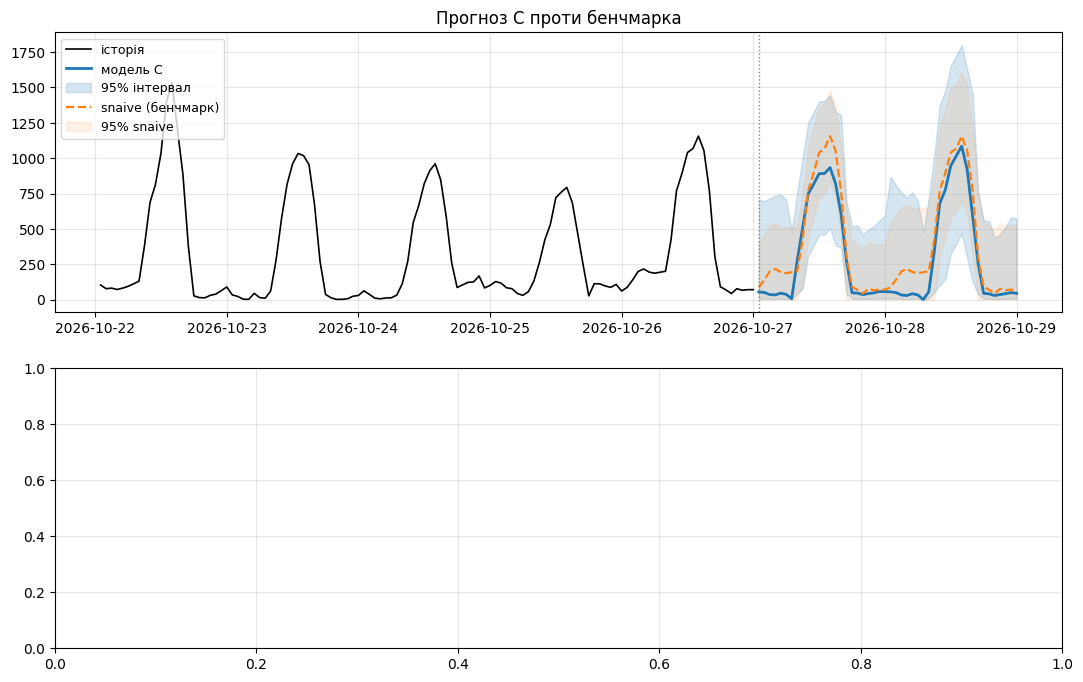

In [29]:
forecast, lower_95, upper_95 = my_forecast(data, weather_fc)
sn_p, sn_lo, sn_hi = snaive(y)
night = prep(weather_fc)["daylight"].to_numpy() == 0

print("                  модель   snaive")
print("середнє           %6.0f   %6.0f" % (forecast.mean(), sn_p.mean()))
print("пік доба 1        %6.0f   %6.0f" % (forecast[:24].max(), sn_p[:24].max()))
print("пік доба 2        %6.0f   %6.0f" % (forecast[24:].max(), sn_p[24:].max()))
print("ніч, середнє      %6.0f   %6.0f" % (forecast[night].mean(), sn_p[night].mean()))
print("ширина 95%%        %6.0f   %6.0f" % ((upper_95 - lower_95).mean(), (sn_hi - sn_lo).mean()))

fig, ax = plt.subplots(2, 1, figsize=(13, 8))
ax[0].plot(data["ds"].iloc[-5 * M:], y[-5 * M:], color="black", lw=1.2, label="історія")
ax[0].plot(FUTURE, forecast, color="tab:blue", lw=2, label="модель C")
ax[0].fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.18, label="95% інтервал")
ax[0].plot(FUTURE, sn_p, color="tab:orange", ls="--", lw=1.6, label="snaive (бенчмарк)")
ax[0].fill_between(FUTURE, sn_lo, sn_hi, color="tab:orange", alpha=0.10, label="95% snaive")
ax[0].axvline(FUTURE.iloc[0], color="grey", lw=1, ls=":")
ax[0].set_title("Прогноз C проти бенчмарка")
ax[0].legend(loc="upper left", fontsize=9); ax[0].grid(alpha=0.3)

In [30]:
WINDOWS = 6      # вікна по 48 годин; вікно 1 — те саме, що в шаблоні

rows, parts = [], []
for k in range(WINDOWS, 0, -1):
    end = len(data) - (k - 1) * H
    history, window = data.iloc[:end - H], data.iloc[end - H:end]
    actual = window["y"].to_numpy(float)

    point, lo, hi = my_forecast(history, window)
    rows.append({"window": k, "model": "ARIMAX+C", **score(actual, point, lo, hi)})
    rows.append({"window": k, "model": "snaive", **score(actual, *snaive(history["y"].to_numpy(float)))})

    parts.append(pd.DataFrame({"ds": window["ds"].to_numpy(), "window": k,
                               "actual": actual, "forecast": point,
                               "resid": actual - point}))
    print("вікно", k, "готове")

valid_table = pd.DataFrame(rows)
resid_df = pd.concat(parts, ignore_index=True).sort_values("ds").reset_index(drop=True)

display(valid_table.round(1))
print("\nсереднє по вікнах:")
display(valid_table.groupby("model")[["RMSE", "MAPE", "Winkler", "coverage"]].mean().round(1))

piv = valid_table.pivot(index="window", columns="model", values="RMSE")
mine = [c for c in piv.columns if c != "snaive"][0]
print(f"\nперемог над бенчмарком: {int((piv[mine] < piv['snaive']).sum())}/{len(piv)}")

row = valid_table[(valid_table.model == mine) & (valid_table.window == 1)]
results.loc[mine] = row[["RMSE", "MAPE", "Winkler", "coverage"]].iloc[0]
display(results.round(1))

вікно 6 готове
вікно 5 готове
вікно 4 готове
вікно 3 готове
вікно 2 готове
вікно 1 готове


,window,model,RMSE,MAPE,Winkler,coverage
0,6,ARIMAX+C,333.6,39.0,933.6,1.0
1,6,snaive,389.3,81.8,3211.3,0.8
2,5,ARIMAX+C,214.1,300.3,1135.5,0.9
3,5,snaive,429.7,1127.4,4134.6,0.6
4,4,ARIMAX+C,178.2,95.8,728.4,0.9
5,4,snaive,282.7,2171.9,1798.5,0.8
6,3,ARIMAX+C,153.7,53.3,814.8,1.0
7,3,snaive,202.0,54.9,992.2,0.9
8,2,ARIMAX+C,95.3,380.2,758.9,0.9
9,2,snaive,181.0,390.4,895.8,0.9



середнє по вікнах:


,RMSE,MAPE,Winkler,coverage
model,,,,
ARIMAX+C,183.1,152.2,877.6,0.9
snaive,267.5,646.2,1933.5,0.8



перемог над бенчмарком: 5/6


,RMSE,MAPE,Winkler,coverage
seasonal naive,120.4,51.1,568.5,1.0
ARIMAX+C,123.8,44.9,894.8,1.0


модель: ARIMA(1,0,0)(0,1,1)[24] з регресорами, AICc 9843.6
коефіцієнти:
  ar1                 0.000
  sma1                0.000
  cloud_cover       142.149
  temperature         5.364
  wind_speed         89.534
  humidity           -2.959
  daylight         -262.971
  wind3              -0.554


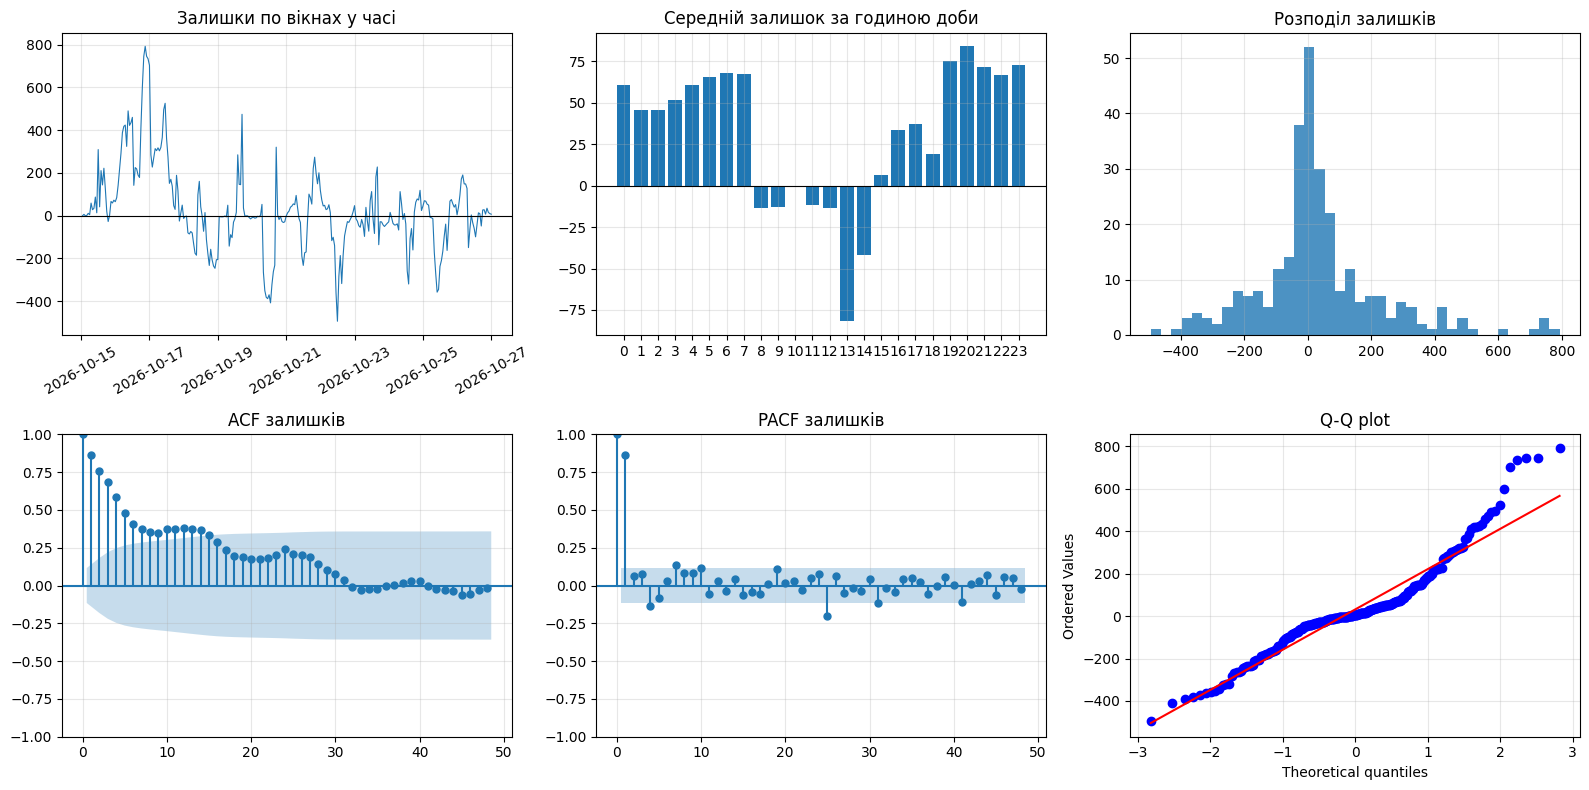

залишки на валідації: n=288, середнє 31.5, с.к.в. 196.5
асиметрія 0.92, ексцес 2.47


,lb_stat,lb_pvalue
24,1227.676,0.0
48,1282.868,0.0


In [35]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import scipy.stats as st

# коефіцієнти саме тієї моделі, яку подаємо
train = prep(data).iloc[-DAYS * M:][["unique_id", "ds", "y"] + XCOLS]
sf_fit = StatsForecast(
    models=[ARIMA(order=(1, 0, 0), seasonal_order=(0, 1, 1), season_length=24)],
    freq="h", n_jobs=1)
sf_fit.fit(train)
m = sf_fit.fitted_[0, 0].model_
print("модель: ARIMA(1,0,0)(0,1,1)[24] з регресорами, AICc %.1f" % m["aicc"])
print("коефіцієнти:")
for name, v in zip(["ar1", "sma1"] + XCOLS, m["coef"].values()):
    print("  %-14s %10.3f" % (name, v))

res = resid_df["resid"]

fig, ax = plt.subplots(2, 3, figsize=(16, 8))

ax[0, 0].plot(resid_df["ds"], res, lw=0.8)
ax[0, 0].axhline(0, color="black", lw=0.8)
ax[0, 0].set_title("Залишки по вікнах у часі")
ax[0, 0].tick_params(axis="x", rotation=30)

byh = resid_df.groupby(resid_df["ds"].dt.hour)["resid"].mean()
ax[0, 1].bar(byh.index, byh.values)
ax[0, 1].axhline(0, color="black", lw=0.8)
ax[0, 1].set_title("Середній залишок за годиною доби")
ax[0, 1].set_xticks(range(0, 24))

ax[0, 2].hist(res, bins=40, color="tab:blue", alpha=0.8)
ax[0, 2].set_title("Розподіл залишків")

plot_acf(res, lags=48, ax=ax[1, 0]);  ax[1, 0].set_title("ACF залишків")
plot_pacf(res, lags=48, ax=ax[1, 1], method="ywm");  ax[1, 1].set_title("PACF залишків")
st.probplot(res, dist="norm", plot=ax[1, 2]);  ax[1, 2].set_title("Q-Q plot")

plt.tight_layout(); plt.show()

print("залишки на валідації: n=%d, середнє %.1f, с.к.в. %.1f" % (len(res), res.mean(), res.std()))
print("асиметрія %.2f, ексцес %.2f" % (st.skew(res), st.kurtosis(res)))
display(acorr_ljungbox(res, lags=[24, 48], model_df=0).round(4))

## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

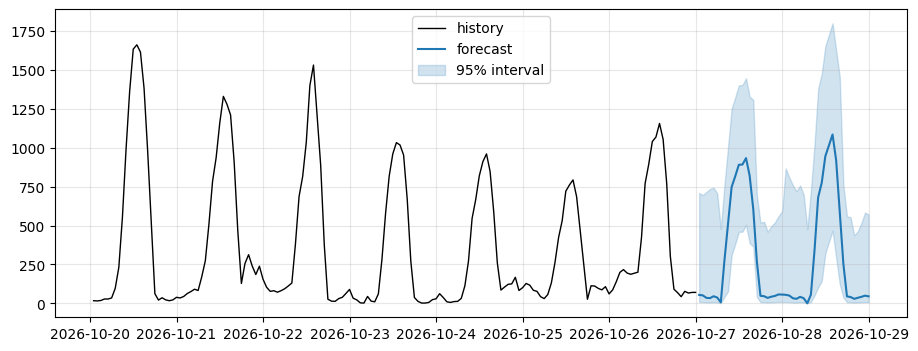

In [36]:
forecast, lower_95, upper_95 = my_forecast(data, weather_fc)     # <-- replace with your model's forecast and 95% interval

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

In [37]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved MIKHAILISHYNA_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.